# Recovering from an error, given to the seed

`06` ended with PPO moving the sampled policy (dev reward 0.702 to 0.830 at T=1) and one error capping every run: a
simulate call fed a number in the wrong unit, then retried with another argument nudged. At the last checkpoint a sampled
episode whose simulate call erred still decided right 0.26 of the time, one without such an error 0.96 (the seed: 0.15
and 0.88). The reference episodes never err, so the seed had no recovery to copy.

This notebook gives the seed one and keeps everything else of 06: the questions, the tools, the reward, the harness,
and 06's stable PPO configuration (the turn as the unit of credit, the actor at lr 2e-6). **Recovery reference
episodes:** for every train question, a second reference episode with one slip the seed was seen to make -- an input
that needs converting passed as the user stated it, or one argument off by a factor of ten -- then the tool's real
error, then the fix. The seed is the smallest dose that is alive, every fourth of its episodes a recovery episode,
the slipped turn shown to it but not trained. Two corrections came out of reading the first seed and reward: the turn
that leaves the slipped conversion out is no longer trained to end there, and **a simulate call the tool rejects earns
no call credit** (*err0*).

**PPO activated both seeds** (the pre-registered test: step 200 against its own seed, every dev question sampled twice
at T=1, paired by question): +0.253 (95% interval +0.219 to +0.288) from the first seed, +0.264 (+0.222 to +0.306)
from the corrected seed with err0. Held out the gains are as large, and the two step-200 checkpoints tie on every probe:

| policy (T=1, every question twice, err0) | test reward | decision right | whole answer right | holdout_shift reward | decision right | whole answer right |
| --- | --- | --- | --- | --- | --- | --- |
| the seed: 300 episodes, every 4th a recovery episode | 0.416 | 0.421 | 0.315 | 0.363 | 0.338 | 0.221 |
| PPO from it, step 200 | 0.712 | 0.754 | 0.652 | 0.607 | 0.621 | 0.450 |
| the corrected seed (the omission's `<|im_end|>` unlabelled) | 0.449 | 0.473 | 0.346 | 0.349 | 0.317 | 0.192 |
| PPO from it with err0, step 200 | 0.714 | 0.738 | 0.640 | 0.608 | 0.558 | 0.396 |
| the same with provenance, step 200 | 0.664 | 0.702 | 0.613 | 0.587 | 0.558 | 0.404 |

- **Recovery grew under PPO more than from the seed.** Against 06's seed of the same 300 episodes, the recovery seed
  samples no better on dev (reward −0.019, −0.053 to +0.015), and an episode whose simulate call errs decides right 0.172
  against 0.111 (unpaired, the interval spanning 0). On the forced probe, 144 dev episodes that start with a unit slip and
  its error, it is +0.148 (+0.097 to +0.198). PPO took decisions among the erring episodes from 0.172 to 0.309 and the
  erring share from 0.423 to 0.229 -- about what 06's PPO did from a seed with no recovery episodes (0.144 to 0.259),
  so this notebook does not separate what the recovery episodes bought from what PPO grows by itself.
- **After step 200 every run loses the convert-first habit.** Continued to 400 with nothing changed, the corrected
  run's dev reward falls (−0.045, −0.084 to −0.005): its L1 episodes (one decimal shift or relabel) simulate first with
  the conversion done in the head, or with the stated number. Whether the first call converts is decided at one token,
  shared by every question; its log-odds random-walks from step 50 on, in every group together. Most of the push in
  the steps measured came from the L0 questions, where simulating first is right; and from step 100 on the reward no
  longer told the two routes apart on L1, because the conversions done in the head were right on train (held out they
  are right less often).
- **Five attempts, each changing one or two things, none better than the control at the same step** (batch token mean,
  first-turn TD with lambda 0 and 0.5, actor lambda 0.5, provenance). All five passed their gates against the seed; none
  stopped the route's swings. The last, *provenance* -- only a conversion convert_units returned in an earlier turn
  proves a point -- restored the reward's preference for converting first and met its pre-registered readout by the
  letter, but at step 200 its route had swung to simulate-first again, and its L1 episodes pass the stated number, are
  rejected, and only then convert.
- **Open:** whether the route's random walk is the noise of eight questions a step. `09_questions_per_step` runs four
  times the questions per step at half the actor step.

**The other notebook 07.** [`07_recover_from_errors`](07_recover_from_errors.ipynb) asks the same question on Apple
silicon (MPS): its seed is 200 of 06's reference episodes and 100 recovery episodes, unconverted inputs only, each fix
opened by a line naming the input; its PPO run is 120 steps on 06's reward. Its numbers and this notebook's are not
comparable as they stand: its probes fold the adapter into bf16 weights for generation (here never), sample 120 dev
questions once (here all 240 twice) and score with 06's reward (here with err0 where marked). The one comparison of the
two seed recipes on the same questions, both trained and probed on that machine, is in [`08_prover_critic`](08_prover_critic.ipynb)
("Three seeds"): this notebook's first-seed recipe scores 0.489 against 0.430 on its 120 dev questions at T=1, and 0.551
against 0.686 on the forced probe.

The splits and the clean reference episodes are 06's, read in place; only the recovery episodes are this notebook's data.
Nothing trains on the MembraneClaw benchmark. Every number below is computed from the runs' saved records; the GPU probes
(the teacher-forced route probe and the gradient attribution) are read from their outputs in `07_error_recovery_diag/`.

In [1]:
import collections, importlib.util, json, math, random, statistics as st, sys
from pathlib import Path

import matplotlib.pyplot as plt

HERE = Path.cwd() if (Path.cwd() / "07_error_recovery.py").exists() else Path("experiments/notebooks/smoke_test35")
# This notebook's own module (06's, copied and changed as its header says); loaded by path because the
# file name starts with a digit. Scoring and the tools are pure Python: nothing below needs WaterTAP or a GPU.
spec = importlib.util.spec_from_file_location("nr07", HERE / "07_error_recovery.py")
nr = importlib.util.module_from_spec(spec)
sys.modules["nr07"] = nr
spec.loader.exec_module(nr)
RUNS, RUNS06, DIAG = nr.RUNS, HERE / "06_direction_and_compare_runs", HERE / "07_error_recovery_diag"
CASES = {c["id"]: c for s in nr.SPLITS for c in nr.load_split(s)}
# the arguments a question states in another unit than the tool's: what convert_units is for
NEED = {q: {t[1] for p in nr.convert_plan(c, limits=False) for t in p["targets"] if t[0] == "arg"} for q, c in CASES.items()}

SEED06 = RUNS / "06-label-seed-n300" / "epoch1"          # 06's 300-episode seed (06's adapter, probed here)
SEEDS = {n: RUNS / f"recovery-seed-n{n}" / "epoch1" for n in ("150", "300", "300-unit", "300-maskend", "300-unit-maskend")}
ORIG, CENTRE, NEW = "ppo-n300-turn-lr2e6-s0", "ppo-n300-turn-lr2e6-center-s0", "ppo-n300-maskend-turn-lr2e6-err0-s0"
NEW400, LNB = NEW + "-to400", NEW + "-from200-lnbatch"
TD0, TD05, ALAM, PROV = (f"ppo-n300-maskend-turn-lr2e6-err0-{k}-s0" for k in ("delta-td0", "delta-td05", "delta-alam05", "prov"))


def rows_of(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def eps(d, stem):
    """A probe's episodes, <dir>/<stem>.episodes.jsonl. A stem ending in -err0 is the probe re-scored with no call credit
    for a simulate call the tool rejected; -err0-prov also with provenance (both are explained below)."""
    return rows_of(Path(d) / f"{stem}.episodes.jsonl")


def last_attempt(rows):
    """Per step, the rows of the attempt that wrote it last (a resumed run writes the steps after its checkpoint again)."""
    out = []
    for r in rows:
        if out and r["step"] < out[-1]["step"]:
            out = [x for x in out if x["step"] < r["step"]]
        out.append(r)
    return out


def samples(run):
    return last_attempt(rows_of(RUNS / run / "samples.jsonl"))


def evals(run):
    return {r["step"]: r for r in last_attempt(rows_of(RUNS / run / "eval.jsonl"))}


def tool_result(c):
    """A stored call's tool result as the harness gave it, for scoring: convert_units recomputed (it is deterministic), a
    rejected call an error, any other call accepted (the score reads only whether a call erred and what it was passed)."""
    a = c["arguments"] if isinstance(c["arguments"], dict) else {}
    if c.get("error"):
        return '{"error": "rejected"}'
    if c["name"] == nr.CONVERT:
        return nr.convert_units(a.get("value"), str(a.get("from_unit", "")), str(a.get("to_unit", "")))
    return '{"ok": 1}'


def score_as(case, calls, text, err_call_credit=True, provenance=False):
    nr.ERR_CALL_CREDIT, nr.PROVENANCE = err_call_credit, provenance
    try:
        return nr.score(case, [dict(c, result=tool_result(c)) for c in calls], text)
    finally:
        nr.ERR_CALL_CREDIT, nr.PROVENANCE = True, False


def rescore(rows, err_call_credit=False, provenance=False):
    """Stored probe episodes scored again under another reward, after checking that they reproduce their stored score."""
    out = []
    for r in rows:
        case = CASES[r["id"]]
        assert abs(score_as(case, r["calls"], r["final_text"])["total"] - r["score"]["total"]) < 1e-9, r["id"]
        s = score_as(case, r["calls"], r["final_text"], err_call_credit, provenance)
        out.append(r | {"score": {k: s[k] for k in ("total", "components", "evidence", "decision_correct")}})
    return out


reward = lambda r: r["score"]["total"]
decided = lambda r: float(bool(r["score"]["decision_correct"]))
sim_erred = lambda r: float(any(x["name"] == CASES[r["id"]]["tool"] and x["error"] for x in r["calls"]))
recovered = lambda r: float(nr.recovered(CASES[r["id"]], r["calls"]))


def whole(r):
    """The whole answer right: it parses, and the decision, the violations and every number are right."""
    s, c = r["score"], r["score"]["components"]
    return float(bool(s["decision_correct"]) and c.get("format", 0) == 1 and c.get("violations", 1) == 1 and c.get("values", 1) == 1)


def by_question(rows, f):
    q = collections.defaultdict(list)
    for r in rows:
        q[r["id"]].append(f(r))
    return {k: sum(v) / len(v) for k, v in q.items()}


def paired(a, b, f=reward):
    """b - a, paired by question (each question's mean over its samples): mean, 95% interval, questions up, down."""
    qa, qb = by_question(a, f), by_question(b, f)
    d = [qb[k] - qa[k] for k in qa if k in qb]
    m, se = st.mean(d), st.pstdev(d) / math.sqrt(len(d))
    return m, m - 1.96 * se, m + 1.96 * se, sum(x > 0 for x in d), sum(x < 0 for x in d)


def pair_text(p):
    return f"{p[0]:+.3f} ({p[1]:+.3f} to {p[2]:+.3f}; questions up {p[3]}, down {p[4]})"


def measures(rows):
    err = [r for r in rows if sim_erred(r)]
    m = lambda f, rs: st.mean(map(f, rs)) if rs else float("nan")  # noqa: E731
    return {"n": len(rows), "reward": m(reward, rows), "decision": m(decided, rows), "whole": m(whole, rows),
            "erring": m(sim_erred, rows), "decision | erring": m(decided, err), "recovered | erring": m(recovered, err)}


def show(named):
    """One line per probe: reward, decision right, whole answer right, the share of episodes with a simulate call the tool
    rejected (erring), and among those the decision right and the erring candidate simulated again cleanly (recovered)."""
    print(f"   {'':48} {'n':>4} {'reward':>7} {'decision':>8} {'whole':>6} {'erring':>7} {'decision|err':>12} {'recovered|err':>13}")
    for label, rows in named:
        m = measures(rows)
        print(f"   {label:48} {m['n']:4} {m['reward']:7.3f} {m['decision']:8.3f} {m['whole']:6.3f} {m['erring']:7.3f} "
              f"{m['decision | erring']:12.3f} {m['recovered | erring']:13.3f}")


def diff(label, a, b, what=("reward", "decision", "whole", "erring"), among_erring=True):
    fs = {"reward": reward, "decision": decided, "whole": whole, "erring": sim_erred}
    print(f"   {label}")
    for k in what:
        print(f"      {k:9} {pair_text(paired(a, b, fs[k]))}")
    if among_erring:
        ea, eb = [r for r in a if sim_erred(r)], [r for r in b if sim_erred(r)]
        pa, pb = st.mean(map(decided, ea)), st.mean(map(decided, eb))
        se = math.sqrt(pa * (1 - pa) / len(ea) + pb * (1 - pb) / len(eb))
        print(f"      decision right among erring episodes {pb - pa:+.3f} ({pb - pa - 1.96 * se:+.3f} to {pb - pa + 1.96 * se:+.3f}; "
              f"unpaired, n {len(ea)} vs {len(eb)})")


GROUPS = ["L0", "L1 one unit", "L1 2+ units", "L2"]


def group(q):
    """The question's unit level: L0 every input in the tool's units; L1 a decimal shift or a relabel, of one input or of
    two or more; L2 a multiplicative conversion. (A level-1 or -2 question whose only conversions are limits is in none.)"""
    c = CASES[q]
    if c["level"] == 0:
        return "L0"
    if not NEED[q]:
        return None
    if c["level"] == 1:
        return "L1 one unit" if len(NEED[q]) == 1 else "L1 2+ units"
    return "L2"


def first_route(r):
    """How the episode starts: "convert" (a convert_units call first), or a simulate call first and how it went --
    "sim:rejected", "sim:right" (accepted, every input that needs converting right: converted in the head), "sim:wrong"."""
    calls, case = r["calls"], CASES[r["id"]]
    if not calls:
        return "none"
    c = calls[0]
    if c["name"] == nr.CONVERT:
        return "convert"
    if c["name"] != case["tool"]:
        return "other"
    if c.get("error"):
        return "sim:rejected"
    a = c["arguments"] if isinstance(c["arguments"], dict) else {}
    right = all(any(k in p["args"] and nr._same_arg(a.get(k), p["args"][k]) for p in case["points"]) for k in NEED[r["id"]])
    return "sim:right" if right else "sim:wrong"


DECISIONS = rows_of(DIAG / "decisions.jsonl")   # the teacher-forced route probe (below), one row per checkpoint
print({s: len(nr.load_split(s)) for s in nr.SPLITS}, "| tools:", ", ".join(nr.ALL_TOOLS))

{'train': 1200, 'dev': 240, 'test': 240, 'holdout_shift': 120} | tools: simulate_ro, simulate_swro_system, convert_units, check_limits


## The recovery episodes

For every train question, a second reference episode with one slip in it, of a kind the seed was seen to make on dev.
An **unconverted** slip passes an input that needs converting to the simulator as the user stated it -- about two thirds of
06's seed's first erroring simulate calls were this -- and every question with a number to convert gets one when one
qualifies; otherwise a **factor** slip puts one argument of one candidate off by ten (x10 or x0.1). The slipped turn
runs on the real tool and the tool's real error comes back; the next turns fix it -- the missing conversion and the
slipped candidates simulated again, or the slipped candidate simulated again with the right number -- and the episode
goes on as the clean one does. A slip qualifies only when the tool errs on every call it touches and the episode stays
inside the simulation budget: a slip the simulator runs silently (a flow in t/h, a temperature in °F) has no error to
read and is never made.

In the seed the slipped turn is context, not a label: the seed reads it and the error, and is trained on the fix and
what follows. An unconverted slip is made one turn earlier than it shows: the conversion turn before it converts the
other inputs and leaves this one out (`ro_check-train-00000` below converts three inputs, then passes 31.1 g/kg as a mass
fraction).

In [2]:
summary = json.loads((nr.REC_DATA / "train_reference_recovery_summary.json").read_text())
recs = rows_of(nr.REC_DATA / "train_reference_recovery.jsonl")
print(f"recovery episodes: {summary['episodes']} (one per train question); slips {summary['slips']}; "
      f"reward mean {st.mean(r['reward'] for r in recs):.3f}, min {min(r['reward'] for r in recs):.3f}")
print("unconverted, by unit:", ", ".join(f"{k} {v}" for k, v in sorted(summary["unconverted, by unit"].items(), key=lambda kv: -kv[1])))
print("factor, by argument:", ", ".join(f"{k} {v}" for k, v in sorted(summary["factor, by argument"].items(), key=lambda kv: -kv[1])))


def show_episode(r, width=140):
    print(f"\n== {r['id']}: slip {r['slip']}, reward {r['reward']:.3f}")
    for i, t in enumerate(r["turns"]):
        print(f"  turn {i}{'  (context: read, not trained)' if t.get('context') else ''}")
        for c, res in zip(t["calls"], t["results"]):
            print(f"     {c['name']} {json.dumps(c['arguments'], ensure_ascii=False)[:width]}")
            print(f"        -> {' '.join(res.split())[:width]}")
    print(f"  answer {r['answer'][:width]}")


show_episode(next(r for r in recs if r["id"] == "ro_check-train-00000"))
show_episode(next(r for r in recs if r["id"] == "swro_option-train-00005"))

recovery episodes: 1200 (one per train question); slips {'unconverted': 662, 'factor': 538}; reward mean 0.952, min 0.896
unconverted, by unit: kPa -> bar 127, MPa -> bar 110, % -> fraction 66, ‰ -> mass fraction 48, L/s -> m³/s 42, % -> mass fraction 39, mg/kg -> mass fraction 37, g/kg -> mass fraction 32, ft² -> m² 31, LMH/bar -> m/s/Pa 26, LMH -> m/s 26, psi -> bar 23, mg/L -> g/L 21, kg/h -> kg/s 13, m³/d -> m³/s 10, m³/h -> m³/s 7, MGD -> m³/s 4
factor, by argument: membrane_area_m2 x10 60, feed_temperature_c x10 59, feed_pressure_bar x0.1 58, feed_flow_mass_kg_s x0.1 53, feed_pressure_bar x10 51, feed_nacl_mass_frac x10 46, A_comp x10 35, feed_tds_g_L x10 26, feed_flow_m3_s x10 24, feed_nacl_mass_frac x0.1 22, p1_pressure_bar x0.1 21, p1_pressure_bar x10 19, feed_flow_m3_s x0.1 18, pxr_efficiency x10 13, p1_efficiency x10 12, feed_tds_g_L x0.1 8, erd_efficiency x10 7, B_comp x0.1 3, feed_flow_mass_kg_s x10 2, membrane_area_m2 x0.1 1

== ro_check-train-00000: slip {'kind': 'unconv

## The seed: the smallest alive dose

06's rule: plain SFT (LoRA r16, one epoch, lr 1e-4, every token of the calls and the answer labelled) on the first *N*
reference episodes of 06's shuffle -- here every fourth replaced by its question's recovery episode -- each dose sampled
once per dev question at T=1, and alive when every behaviour label has been sampled at least once and each of the 16
answer classes decided right at least once. One label is added: after an erroring simulate call, the same candidate
simulated cleanly. The ladder started at 150 episodes. 150 is not alive: the four "none" classes (no option meets the
limits) are never decided right. 300 is, with the new label at 0.083; it is the seed PPO starts from.

In [3]:
for n in ("150", "300"):
    rows = eps(SEEDS[n], "dev-T1-stop")
    L = nr.labels_of(rows, CASES)
    never = [f"{f}:{c}" for (f, c), v in sorted(L["classes"].items()) if v[0] == 0]
    print(f"{n} episodes, every dev question sampled once at T=1 ({L['n']} episodes): {'ALIVE' if L['alive'] else 'not alive'}")
    for k in nr.LABELS:
        print(f"   {k:66} {L['rate'][k]:6.3f}{'' if L['hit'][k] else '  dead'}")
    print(f"   answer classes right at least once: {sum(v[0] > 0 for v in L['classes'].values())}/{len(L['classes'])}"
          + (f"; never right: {', '.join(never)}" if never else ""))

150 episodes, every dev question sampled once at T=1 (240 episodes): not alive
   a tool call parsed                                                  1.000
   a simulate call of the question's tool, ran                         0.583
   a convert_units call, ran                                           0.533
   a check_limits call, ran                                            0.542
   the proving simulations                                             0.179
   a comparison line with a verdict                                    0.471
   the aggregation line (scan questions)                               0.325
   an answer JSON parsed                                               0.450
   the decision right                                                  0.225
   after an erroring simulate call, that candidate simulated cleanly   0.037
   answer classes right at least once: 12/16; never right: ro_membrane:none, ro_scan_area:none, ro_scan_pressure:none, swro_option:none
300 episodes, e

### Against 06's seed of the same dose

The same 300 questions in the same order; 75 of the episodes are recovery episodes (39 factor slips, 36 unconverted).
Sampled twice on every dev question, the two seeds do not differ (reward −0.019, −0.053 to +0.015). An episode whose
simulate call errs decides right 0.172 against 0.111, and its erring candidate is simulated again cleanly 0.163 against
0.092 -- the direction the recovery episodes aim at, by amounts 480 samples do not establish. The cost shows in the
conversions: convert calls err 0.248 of the time against 0.105, 311 of the 398 errors in 23 episodes that call
convert_units again and again after an error (06: 3 such episodes).

In [4]:
s06, s07 = eps(SEED06, "dev-T1-x2-stop"), eps(SEEDS["300"], "dev-T1-x2-stop")
print("dev, all 240 questions sampled twice at T=1, 03-06's reward")
show([("06: 300 clean reference episodes", s06), ("07: the same 300, every 4th a recovery episode", s07)])
diff("07 - 06, paired by question", s06, s07)
for label, rows in (("06", s06), ("07", s07)):
    ce = [x["error"] for r in rows for x in r["calls"] if x["name"] == nr.CONVERT]
    loops = [r for r in rows if sum(x["name"] == nr.CONVERT and bool(x["error"]) for x in r["calls"]) >= 5]
    in_loops = sum(sum(x["name"] == nr.CONVERT and bool(x["error"]) for x in r["calls"]) for r in loops)
    print(f"   {label}: convert calls erring {sum(ce)} of {len(ce)} ({sum(ce) / len(ce):.3f}); {in_loops} of them in "
          f"{len(loops)} episodes with 5 or more")

dev, all 240 questions sampled twice at T=1, 03-06's reward
                                                       n  reward decision  whole  erring decision|err recovered|err
   06: 300 clean reference episodes                  480   0.509    0.442  0.329   0.431        0.111         0.092
   07: the same 300, every 4th a recovery episode    480   0.490    0.433  0.321   0.423        0.172         0.163
   07 - 06, paired by question
      reward    -0.019 (-0.053 to +0.015; questions up 98, down 126)
      decision  -0.008 (-0.057 to +0.040; questions up 51, down 55)
      whole     -0.008 (-0.054 to +0.037; questions up 42, down 46)
      erring    -0.008 (-0.051 to +0.034; questions up 39, down 41)
      decision right among erring episodes +0.061 (-0.006 to +0.129; unpaired, n 207 vs 203)
   06: convert calls erring 101 of 961 (0.105); 18 of them in 3 episodes with 5 or more
   07: convert calls erring 398 of 1603 (0.248); 311 of them in 23 episodes with 5 or more


## The reward for a rejected call

03-06's reward scores every simulate call by the share of its arguments that are right, whether the tool ran it or not.
A slip and its fix then cost almost nothing: on the dev question below, the unconverted number, rejected, then the
conversion and the call again earns 0.954 against 1.000 for converting first. With **err0** (`--err-call-credit 0`) a
rejected call scores 0 and still counts in the mean over the episode's simulate calls, so the same recovery earns 0.850.
Not calling at all still scores below trying (no call credit, and the decision paid 0.3 of its weight without the
simulations that prove it), so the fix after an error keeps paying. The last column is a later change (provenance,
below). Re-scored with err0 the seeds' sampled reward drops by 0.05 to 0.07, all of it in the episodes with an erring
simulate call. err0 is the reward of every run from the corrected seed on; a probe re-scored with it carries `-err0`
in its file name.

In [5]:
# one dev question, its gold answer, and four ways to reach it
case = CASES["swro_check-dev-00010"]
plan = nr.convert_plan(case, limits=False)
conv = [{"name": nr.CONVERT, "arguments": {"value": p["value"], "from_unit": p["from_unit"], "to_unit": p["to_unit"]}} for p in plan]
sims = [{"name": case["tool"], "arguments": dict(pt["args"])} for pt in case["points"]]
stated = {t[1]: p["value"] for p in plan for t in p["targets"] if t[0] == "arg"}
raw = [{"name": case["tool"], "arguments": {**pt["args"], **stated}, "error": True} for pt in case["points"]]
answer = json.dumps(nr.gold_answer(case))
T = lambda calls, turn: [dict(c, turn=turn, error=c.get("error", False)) for c in calls]  # noqa: E731
WAYS = {"convert with the tool, then simulate": T(conv, 0) + T(sims, 1),
        "simulate with the input converted in the head": T(sims, 0),
        "the head, then the tool, and simulate again": T(sims, 0) + T(conv, 1) + T(sims, 2),
        "the stated number, rejected; the tool; simulate again": T(raw, 0) + T(conv, 1) + T(sims, 2)}
convs_txt = ", ".join(f"{p['value']:g} {p['from_unit']} -> {p['to_unit']}" for p in plan)
print(f"{case['id']}: {convs_txt}; {len(case['points'])} point to prove; the gold answer every time")
print(f"   {'':56} {'03-06':>6} {'err0':>6} {'err0 + provenance':>18}")
for name, calls in WAYS.items():
    r0, r1, r2 = (score_as(case, calls, answer, *flags)["total"] for flags in ((True, False), (False, False), (False, True)))
    print(f"   {name:56} {r0:6.3f} {r1:6.3f} {r2:18.3f}")
print("\ndev T=1 x2, the same episodes under 03-06's reward and under err0")
for label, d in [("06: 300 clean", SEED06), ("07: 300, recovery every 4th", SEEDS["300"]), ("07: omission's <|im_end|> unlabelled", SEEDS["300-maskend"])]:
    a = eps(d, "dev-T1-x2-stop")
    b = eps(d, "dev-T1-x2-stop-err0") if (d / "dev-T1-x2-stop-err0.episodes.jsonl").exists() else rescore(a)
    ea, eb = [r for r in a if sim_erred(r)], [r for r in b if sim_erred(r)]
    print(f"   {label:38} reward {st.mean(map(reward, a)):.3f} -> {st.mean(map(reward, b)):.3f}; the episodes with an erring "
          f"simulate call {st.mean(map(reward, ea)):.3f} -> {st.mean(map(reward, eb)):.3f}, the others {st.mean(reward(r) for r in a if not sim_erred(r)):.3f}")

swro_check-dev-00010: 7600 kPa -> bar; 1 point to prove; the gold answer every time
                                                             03-06   err0  err0 + provenance
   convert with the tool, then simulate                      1.000  1.000              1.000
   simulate with the input converted in the head             1.000  1.000              0.635
   the head, then the tool, and simulate again               0.975  0.975              0.975
   the stated number, rejected; the tool; simulate again     0.954  0.850              0.850

dev T=1 x2, the same episodes under 03-06's reward and under err0


   06: 300 clean                          reward 0.509 -> 0.446; the episodes with an erring simulate call 0.238 -> 0.093, the others 0.714


   07: 300, recovery every 4th            reward 0.490 -> 0.425; the episodes with an erring simulate call 0.280 -> 0.128, the others 0.643


   07: omission's <|im_end|> unlabelled   reward 0.506 -> 0.457; the episodes with an erring simulate call 0.291 -> 0.130, the others 0.604


### The omission, and the factor slips

Two questions about the recipe, checked with three more 300-episode seeds, all alive.

*Is the seed trained on the omission?* In the recipe, the conversion turn that leaves the slipped input out is a label:
the seed is trained to end a conversion turn with a conversion missing (26 of the 36 unconverted slips have such a turn;
in the others the slipped input is the only one to convert). With `--recovery-mask-omission 2` that turn's calls stay
labels and its closing `<|im_end|>` does not: the seed is trained to make the conversions it makes, not to stop there.
Its episodes with an erring simulate call fall from 0.423 to 0.310 (−0.113, −0.163 to −0.062), and on L1 it converts every
input before the first simulate call 0.51 of the time against 0.24. This **corrected seed**, which also samples the
highest reward of the five, is the one the later PPO runs start from.

*Do the factor slips teach retrying with a power of ten?* A seed with unconverted slips only (75 of them) samples as the
recipe does (reward −0.005, −0.047 to +0.037) and does better on the forced probe below, which tests only the unit
slips it was trained on; with the omission's `<|im_end|>` also unlabelled it samples worse (−0.052, −0.090 to −0.014).
The factor slips stay.

In [6]:
def converted_first(r):
    """Every input that needs converting converted (by the tool) before the first simulate call."""
    case, done = CASES[r["id"]], set()
    for c in r["calls"]:
        if c["name"] == case["tool"]:
            break
        if c["name"] == nr.CONVERT and not c["error"] and isinstance(c["arguments"], dict):
            for p in nr.convert_plan(case, limits=False):
                if nr._same_arg(c["arguments"].get("value"), p["value"]):
                    done |= {t[1] for t in p["targets"] if t[0] == "arg"}
    return float(NEED[r["id"]] <= done)


SEED_ROWS = [("06: 300 clean", SEED06), ("07: 300, recovery every 4th", SEEDS["300"]),
             ("07: unconverted slips only", SEEDS["300-unit"]), ("07: the omission's <|im_end|> unlabelled", SEEDS["300-maskend"]),
             ("07: unconverted only, <|im_end|> unlabelled", SEEDS["300-unit-maskend"])]
X2 = {}
for label, d in SEED_ROWS:
    X2[label] = eps(d, "dev-T1-x2-stop-err0") if (d / "dev-T1-x2-stop-err0.episodes.jsonl").exists() else rescore(eps(d, "dev-T1-x2-stop"))
print("dev, all 240 questions sampled twice at T=1, err0")
print(f"   {'':46} {'reward':>7} {'decision':>8} {'erring':>7} {'decision|err':>12} {'recovered|err':>13}  "
      f"{'every input converted before the first simulate call: L1 / L2':>62}")
for label, d in SEED_ROWS:
    m, rows = measures(X2[label]), X2[label]
    lv = {g: st.mean(converted_first(r) for r in rows if CASES[r["id"]]["level"] == g and NEED[r["id"]]) for g in (1, 2)}
    print(f"   {label:46} {m['reward']:7.3f} {m['decision']:8.3f} {m['erring']:7.3f} {m['decision | erring']:12.3f} "
          f"{m['recovered | erring']:13.3f}  {lv[1]:55.2f} / {lv[2]:.2f}")
for label, _ in SEED_ROWS[2:]:
    diff(f"{label} - 07: 300, recovery every 4th (dev x2 err0)", X2[SEED_ROWS[1][0]], X2[label], what=("reward", "decision", "erring"),
         among_erring=False)

dev, all 240 questions sampled twice at T=1, err0
                                                   reward decision  erring decision|err recovered|err   every input converted before the first simulate call: L1 / L2
   06: 300 clean                                    0.446    0.442   0.431        0.111         0.092                                                     0.18 / 0.33
   07: 300, recovery every 4th                      0.425    0.433   0.423        0.172         0.163                                                     0.24 / 0.38
   07: unconverted slips only                       0.420    0.435   0.454        0.225         0.307                                                     0.21 / 0.26
   07: the omission's <|im_end|> unlabelled         0.457    0.448   0.310        0.161         0.195                                                     0.51 / 0.35
   07: unconverted only, <|im_end|> unlabelled      0.373    0.369   0.496        0.202         0.298                   

## PPO

06's fourth run's configuration, unchanged except for its start: the turn as the unit of credit (gamma 1, lambda 0.95 per
turn), actor lr 2e-6, 4 inner epochs, clip 0.2, 8 train questions a step at T=1, KL 0.01 to the seed in the reward,
25 warm-up steps for the critic, 200 steps, and the value head warm-started at the seed's sampled dev reward. The tool
gate is off and the answer-collapse rule on; the critic gate and the convergence rule are 06's. The runs draw the same
train questions in the same order, and every step's eight episodes are recorded.

| PPO from | what else | value head | the run ended | greedy evaluations, 120 dev questions, every 25 steps |
| --- | --- | --- | --- | --- |
| the seed | -- (03-06's reward) | 0.4896 | step 200, budget | 0.579, 0.579, 0.637, 0.723, 0.739, 0.754, 0.759, 0.811, 0.823 |
| the seed | advantages centred | 0.4896 | step 200, budget | 0.579, 0.579, 0.641, 0.784, 0.674, 0.756, 0.818, 0.791, 0.770 |
| the corrected seed | err0 | 0.4566 | step 200, budget | 0.595, 0.595, 0.713, 0.659, 0.620, 0.777, 0.739, 0.787, 0.834 |

Centring subtracts the advantages' mean, taken under the actor loss's weights, from the actor's copy (no division by
their spread; the critic's returns unchanged): the one usual PPO detail these runs did not have. Unlike 06's runs, the greedy evaluations rise: the first run's best is
its last, 0.823 against 0.579 at the start.

In [7]:
def ending(run):
    p = RUNS / run / "ending.json"
    return json.loads(p.read_text()) if p.exists() else {}


PPO3 = [("from 07's seed", ORIG), ("from 07's seed, advantages centred", CENTRE), ("from the <|im_end|>-unlabelled seed, err0", NEW)]
for label, run in PPO3:
    cfg, e, ev = json.loads((RUNS / run / "config.json").read_text()), ending(run), evals(run)
    print(f"{label}: {run}  (start {Path(cfg['start_from']).parent.name}, value head {cfg['value_init_bias']}, "
          f"ended at step {e['stopped_at']}: {e['reason']})")
    print("   greedy, 120 dev questions, reward (decision): " + ", ".join(f"{s} {r['reward']:.3f} ({r['decision_correct']:.3f})" for s, r in sorted(ev.items())))

from 07's seed: ppo-n300-turn-lr2e6-s0  (start recovery-seed-n300, value head 0.4896, ended at step 200: step budget 200 reached)
   greedy, 120 dev questions, reward (decision): 0 0.579 (0.508), 25 0.579 (0.508), 50 0.637 (0.583), 75 0.723 (0.708), 100 0.739 (0.742), 125 0.754 (0.742), 150 0.759 (0.742), 175 0.811 (0.817), 200 0.823 (0.817)
from 07's seed, advantages centred: ppo-n300-turn-lr2e6-center-s0  (start recovery-seed-n300, value head 0.4896, ended at step 200: step budget 200 reached)
   greedy, 120 dev questions, reward (decision): 0 0.579 (0.508), 25 0.579 (0.508), 50 0.641 (0.592), 75 0.784 (0.775), 100 0.674 (0.633), 125 0.756 (0.725), 150 0.818 (0.817), 175 0.791 (0.775), 200 0.770 (0.750)
from the <|im_end|>-unlabelled seed, err0: ppo-n300-maskend-turn-lr2e6-err0-s0  (start recovery-seed-n300-maskend, value head 0.4566, ended at step 200: step budget 200 reached)
   greedy, 120 dev questions, reward (decision): 0 0.595 (0.625), 25 0.595 (0.625), 50 0.713 (0.725), 75 0.

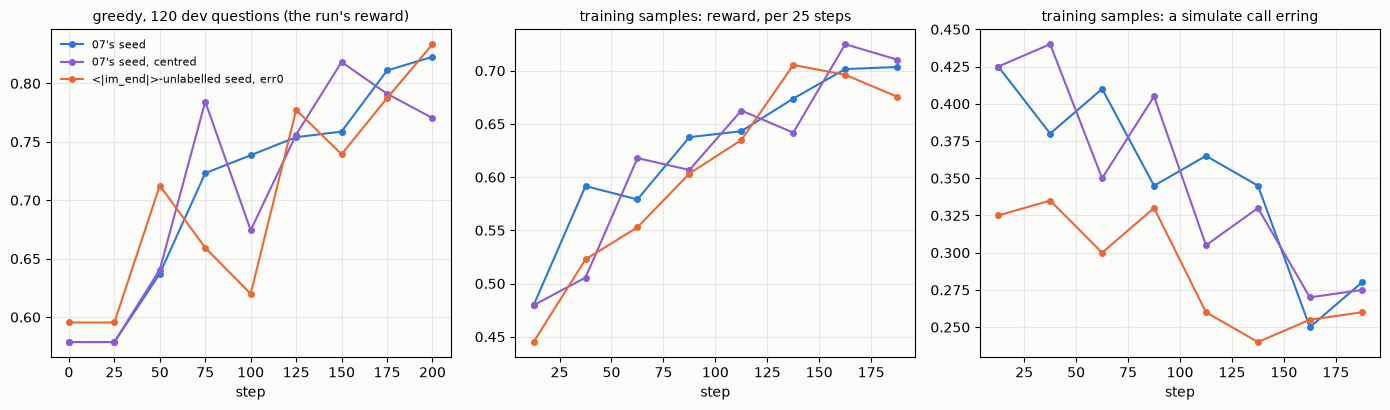

In [8]:
def windows(run, f, lo=0, hi=200, w=25, keep=lambda r: True):
    rows = [r for r in samples(run) if lo <= r["step"] < hi and keep(r)]
    out = []
    for a in range(lo, hi, w):
        x = [f(r) for r in rows if a <= r["step"] < a + w]
        out.append((a + w / 2, st.mean(x) if x else float("nan")))
    return out


s_err = lambda r: float(any(x["name"] == CASES[r["id"]]["tool"] and x["error"] for x in r["calls"]))
COL = {ORIG: "#2a78d6", CENTRE: "#8e5bd6", NEW: "#eb6834"}
LAB = {ORIG: "07's seed", CENTRE: "07's seed, centred", NEW: "<|im_end|>-unlabelled seed, err0"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), facecolor="#fcfcfb")
for ax in axes:
    ax.set_facecolor("#fcfcfb"); ax.grid(color="#e6e6e6", lw=0.8); ax.set_xlabel("step")
for run, c in COL.items():
    ev = evals(run)
    axes[0].plot(sorted(ev), [ev[s]["reward"] for s in sorted(ev)], "o-", color=c, label=LAB[run], ms=4)
    for ax, f in ((axes[1], lambda r: r["reward"]), (axes[2], s_err)):
        xy = windows(run, f)
        ax.plot([x for x, _ in xy], [y for _, y in xy], "o-", color=c, ms=4)
axes[0].set_title("greedy, 120 dev questions (the run's reward)", fontsize=10)
axes[1].set_title("training samples: reward, per 25 steps", fontsize=10)
axes[2].set_title("training samples: a simulate call erring", fontsize=10)
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(HERE / "07_error_recovery_curves.png", dpi=110)
plt.show()

### The pre-registered test: step 200 against its own seed

As set in 06, the policy that counts is the one sampled at T=1, so a run activated its seed when its step-200
checkpoint, sampled twice on every dev question, beats the seed's own samples paired by question with a 95% interval
above 0. All three did. From the seed: +0.253 (+0.219 to +0.288); decisions 0.433 to 0.733, episodes with an erring
simulate call 0.423 to 0.229, and among those the decision right 0.172 to 0.309. Centred: +0.207, but under err0 it is
−0.049 (−0.086 to −0.011) against the uncentred run's step 200, its decisions −0.075; centring is not used again. From
the corrected seed with err0: +0.264 (+0.222 to +0.306). The two uncentred checkpoints tie (+0.016, −0.020 to +0.051).

In [9]:
S7, SM = SEEDS["300"], SEEDS["300-maskend"]
P = {k: RUNS / k / "step200" for k in (ORIG, CENTRE, NEW)}
print("dev, all 240 questions sampled twice at T=1. The pre-registered test: step 200 against its own seed, paired by question.")
show([("07's seed (03-06's reward)", eps(S7, "dev-T1-x2-stop")), ("  PPO from it, step 200", eps(P[ORIG], "dev-T1-x2-stop")),
      ("  the same, centred, step 200", eps(P[CENTRE], "dev-T1-x2-stop")),
      ("<|im_end|>-unlabelled seed (err0)", eps(SM, "dev-T1-x2-stop-err0")), ("  PPO from it with err0, step 200", eps(P[NEW], "dev-T1-x2-stop-err0"))])
diff("PPO from 07's seed, step 200 - its seed (03-06's reward)", eps(S7, "dev-T1-x2-stop"), eps(P[ORIG], "dev-T1-x2-stop"))
diff("the same, centred, step 200 - its seed (03-06's reward)", eps(S7, "dev-T1-x2-stop"), eps(P[CENTRE], "dev-T1-x2-stop"))
diff("PPO from the <|im_end|>-unlabelled seed with err0, step 200 - its seed (err0)", eps(SM, "dev-T1-x2-stop-err0"), eps(P[NEW], "dev-T1-x2-stop-err0"))
print("\nthe step-200 checkpoints against each other, all under err0")
show([(LAB[k] + ", step 200", eps(P[k], "dev-T1-x2-stop-err0")) for k in (ORIG, CENTRE, NEW)])
diff("<|im_end|>-unlabelled seed, err0 - 07's seed", eps(P[ORIG], "dev-T1-x2-stop-err0"), eps(P[NEW], "dev-T1-x2-stop-err0"))
diff("centred - not centred (both from 07's seed)", eps(P[ORIG], "dev-T1-x2-stop-err0"), eps(P[CENTRE], "dev-T1-x2-stop-err0"))

dev, all 240 questions sampled twice at T=1. The pre-registered test: step 200 against its own seed, paired by question.
                                                       n  reward decision  whole  erring decision|err recovered|err
   07's seed (03-06's reward)                        480   0.490    0.433  0.321   0.423        0.172         0.163
     PPO from it, step 200                           480   0.743    0.733  0.658   0.229        0.309         0.318
     the same, centred, step 200                     480   0.696    0.658  0.562   0.260        0.288         0.416
   <|im_end|>-unlabelled seed (err0)                 480   0.457    0.448  0.327   0.310        0.161         0.195
     PPO from it with err0, step 200                 480   0.721    0.731  0.633   0.202        0.289         0.309


   PPO from 07's seed, step 200 - its seed (03-06's reward)
      reward    +0.253 (+0.219 to +0.288; questions up 188, down 27)
      decision  +0.300 (+0.250 to +0.350; questions up 117, down 9)
      whole     +0.338 (+0.285 to +0.390; questions up 127, down 10)
      erring    -0.194 (-0.243 to -0.145; questions up 13, down 81)
      decision right among erring episodes +0.137 (+0.036 to +0.237; unpaired, n 203 vs 110)
   the same, centred, step 200 - its seed (03-06's reward)
      reward    +0.207 (+0.169 to +0.245; questions up 171, down 51)
      decision  +0.225 (+0.167 to +0.283; questions up 103, down 28)
      whole     +0.242 (+0.184 to +0.299; questions up 110, down 29)
      erring    -0.163 (-0.214 to -0.111; questions up 23, down 81)
      decision right among erring episodes +0.116 (+0.021 to +0.210; unpaired, n 203 vs 125)
   PPO from the <|im_end|>-unlabelled seed with err0, step 200 - its seed (err0)
      reward    +0.264 (+0.222 to +0.306; questions up 178, down 

### The forced probe

PR #33's probe: 144 dev episodes whose first turns are given -- a unit slip and the tool's error -- after which the policy
continues greedily. *Recovered*: a simulate call runs cleanly after the first error; *repeats*: identical simulate calls
per episode; *3+*: three or more erroring simulate calls in a row. The recovery seed is +0.148 (+0.097 to +0.198) over
06's, and PPO adds as much again (+0.149, +0.098 to +0.200). The seeds with unconverted slips only are the best
recoverers here (0.840 and 0.847, repeats 0.78 and 0.63 per episode), better than either PPO checkpoint -- on the slip
they were trained on; sampled on dev they were no better (above).

In [10]:
def pr33(calls):
    """PR #33's per-episode recovery measures, on the recorded error flags of the simulate calls."""
    sims = [(c, bool(c["error"])) for c in calls if c["name"] not in nr.LOCAL_TOOLS]
    errs = [e for _, e in sims]
    first = errs.index(True) if True in errs else None
    seen, repeats, run_, streak = set(), 0, 0, 0
    for c, e in sims:
        key = json.dumps([c.get("name"), c.get("arguments")], sort_keys=True, default=str)
        repeats += key in seen
        seen.add(key)
        run_ = run_ + 1 if e else 0
        streak = max(streak, run_)
    return {"erred": first is not None, "recovered": first is not None and not all(errs[first:]), "repeats": repeats, "streak": streak}


FORCED = [("06: 300 clean", SEED06), ("07: 300, recovery every 4th", SEEDS["300"]), ("07: unconverted slips only", SEEDS["300-unit"]),
          ("07: the omission's <|im_end|> unlabelled", SEEDS["300-maskend"]), ("07: unconverted only, <|im_end|> unlabelled", SEEDS["300-unit-maskend"]),
          ("PPO from 07's seed, step 200", RUNS / ORIG / "step200"), ("  the same, centred", RUNS / CENTRE / "step200"),
          ("PPO from the <|im_end|>-unlabelled seed, err0, 200", RUNS / NEW / "step200")]
print("the forced probe: 144 dev episodes whose first turns carry a unit slip and its error, then greedy (03-06's reward)")
print(f"   {'':50} {'reward':>7} {'decision':>8} {'evidence':>8} {'recovered':>9} {'repeats/ep':>10} {'3+ errors in a row':>18}")
for label, d in FORCED:
    rows = eps(d, "dev-T0-stop-forced")
    s = [pr33(r["calls"]) for r in rows]
    er = [x for x in s if x["erred"]]
    print(f"   {label:50} {st.mean(map(reward, rows)):7.3f} {st.mean(map(decided, rows)):8.3f} "
          f"{st.mean(bool(r['score']['evidence']) for r in rows):8.3f} {st.mean(x['recovered'] for x in er):9.3f} "
          f"{st.mean(x['repeats'] for x in s):10.2f} {st.mean(x['streak'] >= 3 for x in s):18.3f}")
a, b = eps(SEED06, "dev-T0-stop-forced"), eps(SEEDS["300"], "dev-T0-stop-forced")
print("   07's seed - 06's, reward, paired:", pair_text(paired(a, b)))
print("   PPO from 07's seed, step 200 - 07's seed:", pair_text(paired(b, eps(RUNS / ORIG / "step200", "dev-T0-stop-forced"))))

the forced probe: 144 dev episodes whose first turns carry a unit slip and its error, then greedy (03-06's reward)
                                                       reward decision evidence recovered repeats/ep 3+ errors in a row
   06: 300 clean                                        0.414    0.312    0.264     0.292       4.55              0.861
   07: 300, recovery every 4th                          0.562    0.458    0.528     0.562       4.17              0.785
   07: unconverted slips only                           0.720    0.694    0.792     0.840       0.78              0.576
   07: the omission's <|im_end|> unlabelled             0.560    0.458    0.535     0.576       3.95              0.792
   07: unconverted only, <|im_end|> unlabelled          0.731    0.701    0.799     0.847       0.63              0.576
   PPO from 07's seed, step 200                         0.711    0.674    0.743     0.792       1.95              0.660
     the same, centred                       

   PPO from the <|im_end|>-unlabelled seed, err0, 200   0.681    0.632    0.681     0.736       2.31              0.681
   07's seed - 06's, reward, paired: +0.148 (+0.097 to +0.198; questions up 52, down 13)
   PPO from 07's seed, step 200 - 07's seed: +0.149 (+0.098 to +0.200; questions up 42, down 8)


### Whose recovery?

06's fourth run had the same PPO configuration and a seed without recovery episodes (600 clean episodes). It moved the
same measures about as far: the erring share 0.260 to 0.169, the decision right among the erring episodes 0.144 to 0.259,
recovered 0.120 to 0.222 (here: 0.423 to 0.229, 0.172 to 0.309, 0.163 to 0.318). PPO grows recovery by itself; how much
the recovery episodes add is not separated here (that control -- 06's 300-episode seed with this PPO -- was not run).

In [11]:
s, p = rows_of(RUNS06 / "label-seed-n600" / "epoch1" / "dev-T1-x2-stop.episodes.jsonl"), rows_of(RUNS06 / "ppo-n600-open-turn-lr2e6-s0" / "step200" / "dev-T1-x2-stop.episodes.jsonl")
print("06's fourth run (the same PPO configuration, from 06's 600-episode seed, no recovery episodes), dev T=1 x2, 03-06's reward")
show([("06: 600-episode seed", s), ("06: its PPO, step 200", p),
      ("07: 07's seed", eps(SEEDS["300"], "dev-T1-x2-stop")), ("07: PPO from it, step 200", eps(RUNS / ORIG / "step200", "dev-T1-x2-stop"))])

06's fourth run (the same PPO configuration, from 06's 600-episode seed, no recovery episodes), dev T=1 x2, 03-06's reward


                                                       n  reward decision  whole  erring decision|err recovered|err
   06: 600-episode seed                              480   0.702    0.683  0.608   0.260        0.144         0.120
   06: its PPO, step 200                             480   0.830    0.840  0.777   0.169        0.259         0.222
   07: 07's seed                                     480   0.490    0.433  0.321   0.423        0.172         0.163
   07: PPO from it, step 200                         480   0.743    0.733  0.658   0.229        0.309         0.318


## Held out

The two seeds and their step-200 checkpoints on test and holdout_shift, sampled twice at T=1 and greedy, all under err0.
Every step-200 checkpoint beats its seed on every probe (test T=1: +0.296 and +0.265; holdout_shift T=1: +0.244 and
+0.259), at every unit level, and the two checkpoints tie on every probe (reward differences +0.001 to +0.004).

In [12]:
HELD = [("07's seed", SEEDS["300"]), ("PPO from it, step 200", RUNS / ORIG / "step200"),
        ("<|im_end|>-unlabelled seed", SEEDS["300-maskend"]), ("PPO from it with err0, step 200", RUNS / NEW / "step200")]
for split in ("test", "holdout_shift"):
    for kind, stem in (("T=1, every question twice", f"{split}-T1-x2-stop-err0"), ("greedy", f"{split}-T0-stop-err0")):
        print(f"{split}, {kind}, err0")
        show([(l, eps(d, stem)) for l, d in HELD])
        R_ = {l: eps(d, stem) for l, d in HELD}
        for a, b in ((HELD[0][0], HELD[1][0]), (HELD[2][0], HELD[3][0]), (HELD[1][0], HELD[3][0])):
            print(f"      {b} - {a}: reward {pair_text(paired(R_[a], R_[b]))}")
            print(f"      {'':{len(b) + len(a) + 3}}  decision {pair_text(paired(R_[a], R_[b], decided))}")
        print()

test, T=1, every question twice, err0


                                                       n  reward decision  whole  erring decision|err recovered|err


   07's seed                                         480   0.416    0.421  0.315   0.402        0.114         0.114
   PPO from it, step 200                             480   0.712    0.754  0.652   0.208        0.270         0.360
   <|im_end|>-unlabelled seed                        480   0.449    0.473  0.346   0.344        0.097         0.103
   PPO from it with err0, step 200                   480   0.714    0.738  0.640   0.200        0.219         0.250
      PPO from it, step 200 - 07's seed: reward +0.296 (+0.250 to +0.343; questions up 178, down 38)
                                         decision +0.333 (+0.278 to +0.389; questions up 122, down 12)
      PPO from it with err0, step 200 - <|im_end|>-unlabelled seed: reward +0.265 (+0.222 to +0.308; questions up 167, down 31)
                                                                    decision +0.265 (+0.214 to +0.316; questions up 119, down 17)
      PPO from it with err0, step 200 - PPO from it, step 200: reward +0.0

      PPO from it, step 200 - 07's seed: reward +0.221 (+0.167 to +0.274; questions up 101, down 17)
                                         decision +0.212 (+0.152 to +0.273; questions up 58, down 7)
      PPO from it with err0, step 200 - <|im_end|>-unlabelled seed: reward +0.149 (+0.099 to +0.198; questions up 81, down 27)
                                                                    decision +0.146 (+0.088 to +0.204; questions up 45, down 10)
      PPO from it with err0, step 200 - PPO from it, step 200: reward +0.002 (-0.034 to +0.037; questions up 38, down 35)
                                                               decision +0.013 (-0.033 to +0.058; questions up 17, down 14)

holdout_shift, T=1, every question twice, err0
                                                       n  reward decision  whole  erring decision|err recovered|err
   07's seed                                         240   0.363    0.338  0.221   0.379        0.132         0.176
   PPO from it, 

      PPO from it, step 200 - 07's seed: reward +0.244 (+0.185 to +0.302; questions up 89, down 22)
                                         decision +0.283 (+0.201 to +0.366; questions up 56, down 12)
      PPO from it with err0, step 200 - <|im_end|>-unlabelled seed: reward +0.259 (+0.203 to +0.315; questions up 96, down 17)
                                                                    decision +0.242 (+0.171 to +0.312; questions up 52, down 8)
      PPO from it with err0, step 200 - PPO from it, step 200: reward +0.001 (-0.054 to +0.056; questions up 48, down 55)
                                                               decision -0.062 (-0.142 to +0.017; questions up 25, down 36)

holdout_shift, greedy, err0
                                                       n  reward decision  whole  erring decision|err recovered|err
   07's seed                                         120   0.509    0.467  0.375   0.292        0.171         0.286
   PPO from it, step 200            

In [13]:
print("the gain by unit level, seed -> step 200: reward (decision right), T=1 x2, err0")
for pair in (HELD[:2], HELD[2:]):
    print(f" {pair[0][0]} -> {pair[1][0]}")
    for split in ("dev", "test", "holdout_shift"):
        rows = {l: eps(d, f"{split}-T1-x2-stop-err0") for l, d in pair}
        cells = []
        for lv in (0, 1, 2):
            a, b = ([r for r in rows[l] if CASES[r["id"]]["level"] == lv] for l, _ in pair)
            cells.append(f"L{lv} {st.mean(map(reward, a)):.3f} -> {st.mean(map(reward, b)):.3f} ({st.mean(map(decided, a)):.2f} -> {st.mean(map(decided, b)):.2f})")
        print(f"   {split:13} " + " | ".join(cells))

the gain by unit level, seed -> step 200: reward (decision right), T=1 x2, err0
 07's seed -> PPO from it, step 200
   dev           L0 0.659 -> 0.874 (0.66 -> 0.88) | L1 0.300 -> 0.701 (0.34 -> 0.75) | L2 0.229 -> 0.434 (0.21 -> 0.47)


   test          L0 0.657 -> 0.844 (0.68 -> 0.89) | L1 0.271 -> 0.718 (0.28 -> 0.77) | L2 0.186 -> 0.488 (0.16 -> 0.52)
   holdout_shift L0 0.497 -> 0.745 (0.42 -> 0.72) | L1 0.347 -> 0.681 (0.37 -> 0.71) | L2 0.202 -> 0.356 (0.20 -> 0.41)
 <|im_end|>-unlabelled seed -> PPO from it with err0, step 200


   dev           L0 0.634 -> 0.881 (0.64 -> 0.92) | L1 0.416 -> 0.730 (0.39 -> 0.74) | L2 0.227 -> 0.443 (0.22 -> 0.42)


   test          L0 0.590 -> 0.854 (0.62 -> 0.88) | L1 0.396 -> 0.688 (0.40 -> 0.71) | L2 0.280 -> 0.513 (0.30 -> 0.52)
   holdout_shift L0 0.475 -> 0.733 (0.45 -> 0.68) | L1 0.302 -> 0.605 (0.26 -> 0.51) | L2 0.223 -> 0.446 (0.19 -> 0.43)


## After step 200

The corrected run continued from its step 200 to 400 with nothing changed; the convergence rule ended it at 400, no
evaluation having beaten step 200's 0.834 (they ran 0.73 to 0.79). Sampled on dev, step 400 is −0.045 (−0.084 to
−0.005) against step 200, with more episodes erring (+0.092). What changed is how the L1 episodes start. At step 200,
0.60 of the L1 one-unit episodes and 0.93 of the L1 2+ ones converted first; at step 400, 0.25 and 0.60. The one-unit
episodes now simulate first with the input converted in the head (0.21 to 0.50 of them); the 2+ ones simulate first with
the stated numbers and are rejected (0.06 to 0.37).

In [14]:
ev = evals(NEW400)
print("PPO from the <|im_end|>-unlabelled seed with err0, continued from step 200 to 400 (no other change)")
print("   greedy, 120 dev questions, reward (decision): " + ", ".join(f"{s} {ev[s]['reward']:.3f} ({ev[s]['decision_correct']:.3f})" for s in sorted(ev) if s >= 200))
e = ending(NEW400)
print(f"   ended at step {e['stopped_at']}: {e['reason']}")
d200, d300, d400 = eps(RUNS / NEW / "step200", "dev-T1-x2-stop-err0"), eps(RUNS / NEW400 / "step300", "dev-T1-x2-stop-err0"), eps(RUNS / NEW400 / "step400", "dev-T1-x2-stop-err0")
show([("step 200", d200), ("step 300", d300), ("step 400", d400)])
diff("step 400 - step 200 (dev T=1 x2, err0)", d200, d400)


def route_table(named, groups=("L1 one unit", "L1 2+ units", "L2")):
    """Per question group: the share of episodes by how they start, and the reward of each start."""
    for g in groups:
        print(f"   {g}")
        for label, rows in named:
            rs = [r for r in rows if group(r["id"]) == g]
            by = collections.defaultdict(list)
            for r in rs:
                by[first_route(r)].append(reward(r))
            print(f"      {label:24} n {len(rs):3} | " + " | ".join(
                f"{k} {len(by[k]) / len(rs):.2f} ({st.mean(by[k]):.2f})" for k in ("convert", "sim:right", "sim:rejected", "sim:wrong") if by[k]))


print("\nhow the episodes start (share, and in brackets the mean reward), dev T=1 x2, err0")
route_table([("step 200", d200), ("step 400", d400)])

PPO from the <|im_end|>-unlabelled seed with err0, continued from step 200 to 400 (no other change)
   greedy, 120 dev questions, reward (decision): 200 0.834 (0.858), 225 0.778 (0.817), 250 0.760 (0.783), 275 0.734 (0.750), 300 0.748 (0.767), 325 0.785 (0.792), 350 0.740 (0.742), 375 0.788 (0.808), 400 0.737 (0.758)
   ended at step 400: converged: 8 evaluations without beating 0.8335 (step 200)
                                                       n  reward decision  whole  erring decision|err recovered|err
   step 200                                          480   0.721    0.731  0.633   0.202        0.289         0.309
   step 300                                          480   0.704    0.733  0.662   0.300        0.382         0.396
   step 400                                          480   0.676    0.696  0.583   0.294        0.390         0.440
   step 400 - step 200 (dev T=1 x2, err0)
      reward    -0.045 (-0.084 to -0.005; questions up 73, down 105)
      decision  -0.035 (-

### The route, measured directly

Whether the first call is convert_units is decided at one token: after `<tool_call>\n<function`, "=" then "convert",
against "=s" (simulate). On every saved checkpoint the teacher-forced log-odds of a first convert call was measured on
fixed prompts -- every dev L1/L2 question that needs a conversion, 60 dev L0 questions, 96 train L1/L2 questions
(`07_error_recovery_diag/decision_probe.py`, rows in `decisions.jsonl`). From step 50 the control's log-odds move by
2 to 4 every 25 steps, before step 200 as after it (by up to 12 after step 300), and the four groups move together: L0, where converting first is a
waste, with L1 and L2, where it is right. The training samples (right) follow the probe.

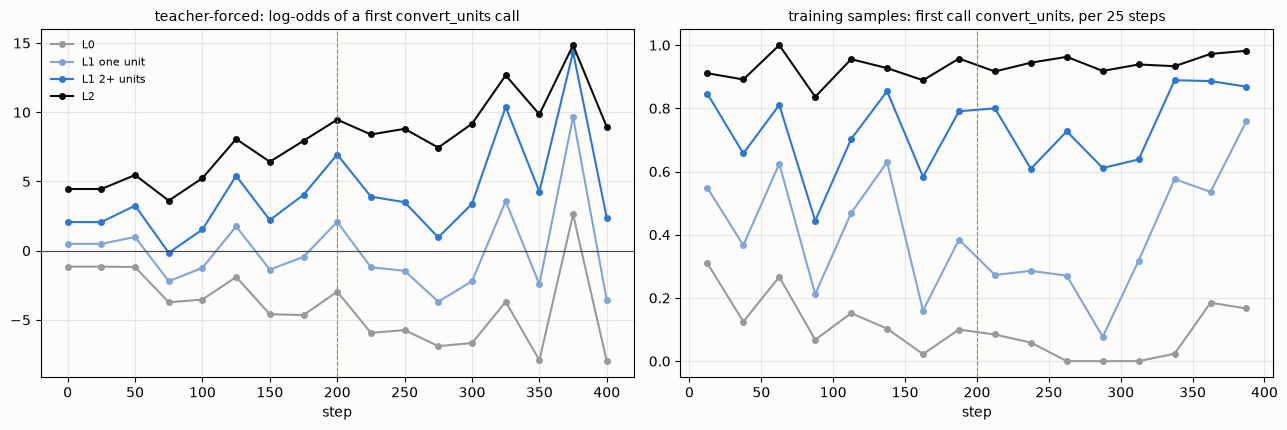

route log-odds, dev groups, every 25 steps:
   dev L0           -1.2 -1.2 -3.7 -3.5 -1.9 -4.6 -4.7 -3.0 -5.9 -5.7 -6.9 -6.7 -3.7 -7.9 +2.6 -8.0
   dev L1 one unit  +0.5 +1.0 -2.2 -1.2 +1.8 -1.4 -0.4 +2.1 -1.2 -1.4 -3.7 -2.2 +3.6 -2.4 +9.7 -3.6
   dev L1 2+ units  +2.1 +3.3 -0.2 +1.5 +5.4 +2.2 +4.0 +6.9 +3.9 +3.5 +1.0 +3.4 +10.4 +4.3 +14.3 +2.4
   dev L2           +4.5 +5.5 +3.6 +5.2 +8.1 +6.4 +7.9 +9.5 +8.4 +8.8 +7.4 +9.2 +12.7 +9.8 +14.8 +8.9


In [15]:
def dec(key, lo=0, hi=400):
    return {r["step"]: r for r in DECISIONS if r["run"] == key and lo <= r["step"] <= hi}


def route_series(key, g, hi=400):
    d = dec(key, hi=hi)
    return sorted(d), [d[s]["route"][g]["log_odds"] for s in sorted(d)]


seed0 = {r["run"]: r for r in DECISIONS if r["step"] == 0}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), facecolor="#fcfcfb")
GC = {"dev L0": "#9a9a9a", "dev L1 one unit": "#7fa6d8", "dev L1 2+ units": "#2a78d6", "dev L2": "#0b0b0b"}
for g, c in GC.items():
    xs, ys = route_series("new", g)
    axes[0].plot([0] + xs, [seed0["seedmaskend"]["route"][g]["log_odds"]] + ys, "o-", color=c, ms=4, label=g[4:])
axes[0].axhline(0, color="#444", lw=0.8)
axes[0].set_title("teacher-forced: log-odds of a first convert_units call", fontsize=10)
axes[0].legend(fontsize=8, frameon=False)
rows = [r for r in samples(NEW400) if r["calls"]]
for g, c in zip(GROUPS, GC.values()):
    xs, ys = [], []
    for a in range(0, 400, 25):
        w = [r for r in rows if a <= r["step"] < a + 25 and group(r["id"]) == g]
        xs.append(a + 12.5); ys.append(st.mean(first_route(r) == "convert" for r in w))
    axes[1].plot(xs, ys, "o-", color=c, ms=4, label=g)
axes[1].set_title("training samples: first call convert_units, per 25 steps", fontsize=10)
for ax in axes:
    ax.set_facecolor("#fcfcfb"); ax.grid(color="#e6e6e6", lw=0.8); ax.set_xlabel("step"); ax.axvline(200, color="#eb6834", lw=0.8, ls="--")
fig.tight_layout()
fig.savefig(HERE / "07_error_recovery_route.png", dpi=110)
plt.show()
print("route log-odds, dev groups, every 25 steps:")
for g in GC:
    xs, ys = route_series("new", g)
    print(f"   {g:16} " + " ".join(f"{y:+.1f}" for y in ys))

### What moves it

From the run's step-200 state (adapter, critic, Adam's moments) and its real batches of steps 200-224, the first-order
change each part of the update makes to the route log-odds (`attribution.py`, `route_attr.py`). The route tokens are moved
by their own gradient, through the task advantage of the simulate-first episodes; the KL penalty and the rest of the
episode move them little. By question group, most of the push comes from L0: 76 of the 200 episodes simulate first on
an L0 question, as they should, with a mean task advantage of +0.22, and through the shared token they push the L1/L2
route toward simulate-first (−1.37 per step). The few simulate-first L1/L2 episodes, which mostly fail, push back. The
estimate holds the step-200 policy and Adam's preconditioner fixed and has no clip: its signs agree with the measured
change, its size does not (−0.61 per step predicted, −0.10 per step measured).

In [16]:
A = json.loads((DIAG / "attr_new.json").read_text())
print(f"steps {A['steps'][0]}-{A['steps'][1]} of the run continued to 400: route log-odds (64 train L1/L2 prompts) {A['J_200']:.2f} -> {A['J_225']:.2f}")
print("first-order change per step, by the tokens it acts on, the part of the advantage, and the episode's first call:")
for k, v in sorted(A["per_step"].items(), key=lambda kv: -abs(kv[1]))[:6]:
    print(f"   {k:48} {v:+.3f}")
ra = [r for r in rows_of(DIAG / "ra_new.jsonl") if not r.get("_meta")]
nstep = len({r["step"] for r in ra})
print("\nthe route tokens' task part, on the train L1 2+ / L2 prompts, by the episode's question group and first call (per step):")
acc, n, adv = collections.defaultdict(float), collections.Counter(), collections.defaultdict(float)
for r in ra:
    if "dJ" in r:
        k = (str(r["group"]), str(r["first"]))
        acc[k] += r["dJ"]["J multi"]["task"] / nstep; n[k] += 1; adv[k] += r["adv_task"]
for k in sorted(n, key=lambda k: -abs(acc[k])):
    print(f"   {k[0]:12} {k[1]:9} {acc[k]:+.3f}   episodes {n[k]:3}, mean task advantage {adv[k] / n[k]:+.3f}")

steps 200-225 of the run continued to 400: route log-odds (64 train L1/L2 prompts) 7.35 -> 4.86
first-order change per step, by the tokens it acts on, the part of the advantage, and the episode's first call:
   route | task | simulate-first                    -1.086
   route | centre | simulate-first                  +0.325
   route | kl | simulate-first                      +0.197
   route | kl | convert-first                       -0.072
   route | centre | convert-first                   -0.051
   first turn, rest | task | convert-first          +0.043

the route tokens' task part, on the train L1 2+ / L2 prompts, by the episode's question group and first call (per step):
   L0           simulate  -1.371   episodes  76, mean task advantage +0.223
   L1 2+ units  simulate  +0.386   episodes   7, mean task advantage -0.452
   L2           simulate  +0.308   episodes   4, mean task advantage -0.429
   L0           convert   +0.068   episodes   7, mean task advantage -0.051
   L1 2+ uni

## Five attempts at the route

Each a fresh run from the corrected seed with the control's configuration and one change (the first-turn TD and actor
lambda runs: two), except the first, a 100-step branch of the control's step 200:

| run | change |
| --- | --- |
| batch token mean | the actor loss averaged over all of the batch's trainable tokens, not over each episode's tokens first |
| first-turn TD, lambda 0 | the first turn's advantage r0 + V(s1) − V(s0), the other turns lambda 0.95; and call credit per turn (each turn earns the change it makes to the calls component, negative when it lowers it) |
| first-turn TD, lambda 0.5 | the same, the first turn at lambda 0.5 |
| actor lambda 0.5 | the actor's advantages at lambda 0.5 on every turn (the critic's returns still at 0.95); call credit per turn |
| provenance | a simulate call proves its point only with inputs that convert_units returned in an earlier turn (below) |

Each had its gate, set before it ran: step 200 against the seed, dev T=1 x2 paired, the interval above 0. All passed.
None beat the control at step 200, and none stopped the swings: the first-turn TD and actor-lambda runs were to halve
them, and the closest, actor lambda 0.5, is 28% and 23% below the control's.

In [17]:
ATTEMPTS = [("the control", NEW, "new"),
            ("one token mean over the batch (from step 200)", LNB, "lnb"),
            ("call credit per turn + first-turn TD, lambda 0", TD0, "td0"),
            ("call credit per turn + first-turn TD, lambda 0.5", TD05, "td05"),
            ("call credit per turn + actor lambda 0.5, every turn", ALAM, "alam05"),
            ("provenance", PROV, "prov")]
SM = SEEDS["300-maskend"]


def swings(key, g, lo=25, hi=200):
    d = dec(key, lo, hi)
    xs = [d[s]["route"][g]["log_odds"] for s in sorted(d)]
    dx = [b - a for a, b in zip(xs, xs[1:])]
    return st.mean(abs(x) for x in dx), sum(x * y < 0 for x, y in zip(dx, dx[1:]))


print("dev T=1 x2 under err0, each run's step 200 (the batch-mean run: step 300, against the control's 300)")
print(f"   {'':52} {'vs its seed':>24} {'vs the control':>24}   {'route swings 25-200: train / dev L1 2+':>40}")
ctl = eps(RUNS / NEW / "step200", "dev-T1-x2-stop-err0")
seed_rows = eps(SM, "dev-T1-x2-stop-err0")
for label, run, key in ATTEMPTS:
    if run == LNB:
        mine, other = eps(RUNS / LNB / "step300", "dev-T1-x2-stop-err0"), eps(RUNS / NEW400 / "step300", "dev-T1-x2-stop-err0")
        vs_seed, sw = "", ""
    else:
        mine, other = eps(RUNS / run / "step200", "dev-T1-x2-stop-err0"), ctl
        p = paired(seed_rows, mine)
        vs_seed = f"{p[0]:+.3f} ({p[1]:+.3f},{p[2]:+.3f})"
        (a, fa), (b, fb) = swings(key, "train L1 2+ units"), swings(key, "dev L1 2+ units")
        sw = f"{a:.2f} / {b:.2f}  (sign changes {fa} / {fb})"
    q = paired(other, mine) if run != NEW else None
    vs_ctl = f"{q[0]:+.3f} ({q[1]:+.3f},{q[2]:+.3f})" if q else "-"
    print(f"   {label:52} {vs_seed:>24} {vs_ctl:>24}   {sw:>40}")

dev T=1 x2 under err0, each run's step 200 (the batch-mean run: step 300, against the control's 300)
                                                                     vs its seed           vs the control     route swings 25-200: train / dev L1 2+
   the control                                            +0.264 (+0.222,+0.306)                        -          2.45 / 2.59  (sign changes 4 / 4)
   one token mean over the batch (from step 200)                                   -0.055 (-0.092,-0.019)                                           
   call credit per turn + first-turn TD, lambda 0         +0.114 (+0.069,+0.160)   -0.149 (-0.188,-0.111)          2.27 / 2.50  (sign changes 5 / 5)
   call credit per turn + first-turn TD, lambda 0.5       +0.211 (+0.170,+0.253)   -0.053 (-0.090,-0.015)          2.47 / 2.66  (sign changes 4 / 4)


   call credit per turn + actor lambda 0.5, every turn    +0.180 (+0.136,+0.224)   -0.084 (-0.125,-0.043)          1.76 / 1.99  (sign changes 2 / 2)
   provenance                                             +0.230 (+0.187,+0.272)   -0.034 (-0.071,+0.003)          2.18 / 2.33  (sign changes 5 / 5)


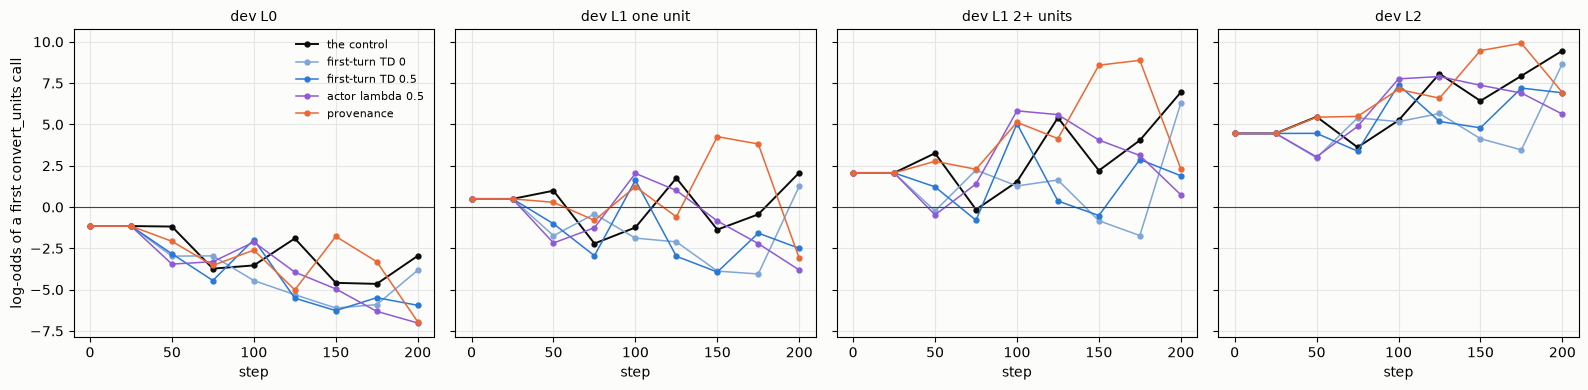

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor="#fcfcfb", sharey=True)
RC = {"new": ("#0b0b0b", "the control"), "td0": ("#7fa6d8", "first-turn TD 0"), "td05": ("#2a78d6", "first-turn TD 0.5"),
      "alam05": ("#8e5bd6", "actor lambda 0.5"), "prov": ("#eb6834", "provenance")}
for ax, g in zip(axes, ("dev L0", "dev L1 one unit", "dev L1 2+ units", "dev L2")):
    for key, (c, lab) in RC.items():
        xs, ys = route_series(key, g, hi=200)
        ax.plot([0] + xs, [seed0["seedmaskend"]["route"][g]["log_odds"]] + ys, "o-", color=c, ms=3.5, lw=1.4 if key == "new" else 1.1, label=lab)
    ax.axhline(0, color="#444", lw=0.8); ax.set_title(g, fontsize=10); ax.set_xlabel("step")
    ax.set_facecolor("#fcfcfb"); ax.grid(color="#e6e6e6", lw=0.8)
axes[0].set_ylabel("log-odds of a first convert_units call")
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(HERE / "07_error_recovery_route_runs.png", dpi=110)
plt.show()

### The reward stops telling the routes apart

The four runs from the corrected seed drew the same train questions at the same steps, so many questions were answered
both ways. Within question, converting first earned more on L1 2+ until step 150 (+0.23 to +0.34), on L1 one unit only
at steps 50-99 (+0.20), and on L2 from step 50 (+0.23 to +0.29 to step 199); on L0 it earned less (−0.16 to −0.34), as it should. From step 100 the L1
one-unit contrast is about 0 (−0.03, −0.05, 0.00, −0.06), and the L1 2+ one falls to +0.13 at 150-199 and −0.01 at
200-249. What closed the gap is the head: among the simulate-first episodes, the share whose first call already had
every input right went from 0.00 to 0.48 on L1 2+ and from 0.41 to 0.70 on L1 one unit, scoring 0.84 to 0.93 from step
100 to 249 -- as much as converting. Re-scored with provenance (next section) the same samples give converting first its margin back on L1
2+ (+0.18, +0.16 after step 150) and part of it on L1 one unit (+0.10, +0.23, n.s. at 150-199). Held out, those head
conversions are right less often: at the control's step 200, half of the simulate-first L1 one-unit episodes on dev and
test, 1 of 8 on holdout_shift.

In [19]:
def within(rows, rng, B=2000):
    """Per question answered both ways: mean reward of the convert-first samples minus the simulate-first ones;
    the mean over those questions and a 95% interval resampling questions (None under 5 questions)."""
    by = collections.defaultdict(lambda: {"convert": [], "sim": []})
    for e in rows:
        by[e["id"]][e["route"]].append(e["reward"])
    d = [st.mean(v["convert"]) - st.mean(v["sim"]) for v in by.values() if v["convert"] and v["sim"]]
    if len(d) < 5:
        return None, len(d)
    bs = sorted(st.mean(rng.choices(d, k=len(d))) for _ in range(B))
    return (st.mean(d), bs[int(.025 * B)], bs[int(.975 * B)]), len(d)


POOL = {"control": NEW400, "td0": TD0, "td05": TD05, "alam05": ALAM}   # the same questions at the same steps
pooled, same = [], 0
for key, run in POOL.items():
    for r in samples(run):
        g, fr = group(r["id"]), first_route(r)
        if g and fr not in ("none", "other"):
            a, b = (score_as(CASES[r["id"]], r["calls"], r["final_text"], False, prov)["total"] for prov in (False, True))
            same += abs(a - r["reward"]) < 1e-9
            pooled.append({"run": key, "step": r["step"], "id": r["id"], "group": g, "route": "convert" if fr == "convert" else "sim",
                           "how": fr, "reward": r["reward"], "prov": b})
print(f"training samples of the four runs that drew the same questions, pooled ({len(pooled)} episodes; the stored reward "
      f"reproduced on {same}); per 50-step phase (200-299: the control and first-turn TD 0.5 only).")
print("within question: convert-first minus simulate-first reward, as trained (err0) and re-scored with provenance (95% interval,")
print("questions answered both ways) | the share of simulate-first episodes whose first call had every input right, and their reward")
rng = random.Random(0)
for g in GROUPS:
    print(f"   {g}")
    for lo in range(0, 300, 50):
        w = [e for e in pooled if e["group"] == g and lo <= e["step"] < lo + 50]
        cells = []
        for k in ("reward", "prov"):
            res, nq = within([dict(e, reward=e[k]) for e in w], rng)
            cells.append(f"{res[0]:+.2f} ({res[1]:+.2f} to {res[2]:+.2f})" if res else f"{'-':^21}")
        sm = [e for e in w if e["route"] == "sim"]
        right = [e["reward"] for e in sm if e["how"] == "sim:right"]
        print(f"      {lo:3}-{lo + 49:3} q{nq:3}  err0 {cells[0]}  provenance {cells[1]} | head-right {len(right) / max(1, len(sm)):.2f}"
              + (f" ({st.mean(right):.2f})" if right else ""))

training samples of the four runs that drew the same questions, pooled (8662 episodes; the stored reward reproduced on 8662); per 50-step phase (200-299: the control and first-turn TD 0.5 only).
within question: convert-first minus simulate-first reward, as trained (err0) and re-scored with provenance (95% interval,
questions answered both ways) | the share of simulate-first episodes whose first call had every input right, and their reward
   L0
        0- 49 q 28  err0 -0.34 (-0.49 to -0.18)  provenance -0.34 (-0.49 to -0.19) | head-right 0.95 (0.76)
       50- 99 q 45  err0 -0.16 (-0.26 to -0.06)  provenance -0.16 (-0.26 to -0.06) | head-right 0.98 (0.84)
      100-149 q 26  err0 -0.20 (-0.38 to -0.03)  provenance -0.20 (-0.39 to -0.03) | head-right 0.98 (0.84)


      150-199 q 14  err0 -0.19 (-0.36 to -0.02)  provenance -0.19 (-0.36 to -0.02) | head-right 0.99 (0.87)
      200-249 q 10  err0 -0.26 (-0.54 to +0.00)  provenance -0.26 (-0.53 to +0.00) | head-right 0.99 (0.88)
      250-299 q  0  err0           -            provenance           -           | head-right 0.97 (0.86)
   L1 one unit
        0- 49 q 11  err0 +0.14 (-0.11 to +0.38)  provenance +0.23 (+0.01 to +0.43) | head-right 0.41 (0.77)
       50- 99 q 25  err0 +0.20 (+0.03 to +0.36)  provenance +0.27 (+0.13 to +0.42) | head-right 0.44 (0.85)
      100-149 q 23  err0 -0.03 (-0.20 to +0.13)  provenance +0.07 (-0.07 to +0.21) | head-right 0.52 (0.93)


      150-199 q 16  err0 -0.05 (-0.20 to +0.08)  provenance +0.10 (-0.03 to +0.21) | head-right 0.69 (0.91)
      200-249 q  8  err0 +0.00 (-0.18 to +0.16)  provenance +0.23 (+0.02 to +0.37) | head-right 0.61 (0.86)
      250-299 q  6  err0 -0.06 (-0.45 to +0.31)  provenance +0.08 (-0.18 to +0.29) | head-right 0.70 (0.88)
   L1 2+ units
        0- 49 q 17  err0 +0.28 (+0.06 to +0.47)  provenance +0.31 (+0.14 to +0.48) | head-right 0.00
       50- 99 q 33  err0 +0.23 (+0.13 to +0.32)  provenance +0.24 (+0.16 to +0.33) | head-right 0.04 (0.52)


      100-149 q 31  err0 +0.34 (+0.21 to +0.48)  provenance +0.42 (+0.31 to +0.53) | head-right 0.07 (0.89)
      150-199 q 40  err0 +0.13 (+0.02 to +0.24)  provenance +0.18 (+0.09 to +0.27) | head-right 0.21 (0.89)
      200-249 q 32  err0 -0.01 (-0.16 to +0.14)  provenance +0.16 (+0.01 to +0.30) | head-right 0.48 (0.84)
      250-299 q 19  err0 +0.14 (-0.07 to +0.35)  provenance +0.19 (-0.00 to +0.38) | head-right 0.44 (0.68)
   L2
        0- 49 q  9  err0 +0.02 (-0.09 to +0.13)  provenance +0.02 (-0.09 to +0.12) | head-right 0.00


       50- 99 q 19  err0 +0.23 (+0.09 to +0.37)  provenance +0.19 (+0.08 to +0.30) | head-right 0.00
      100-149 q 14  err0 +0.29 (+0.11 to +0.45)  provenance +0.30 (+0.16 to +0.45) | head-right 0.06 (1.00)
      150-199 q 21  err0 +0.26 (+0.15 to +0.37)  provenance +0.25 (+0.17 to +0.33) | head-right 0.09 (0.90)
      200-249 q 15  err0 +0.23 (-0.03 to +0.48)  provenance +0.30 (+0.09 to +0.50) | head-right 0.10 (0.97)
      250-299 q  6  err0 +0.09 (-0.04 to +0.25)  provenance +0.18 (+0.01 to +0.35) | head-right 0.00


In [20]:
print("at step 200 of the control, T=1 x2: simulate-first episodes whose first simulate call had every input right")
for g in ("L1 one unit", "L1 2+ units"):
    cells = []
    for split in ("dev", "test", "holdout_shift"):
        rows = [r for r in eps(RUNS / NEW / "step200", f"{split}-T1-x2-stop-err0") if group(r["id"]) == g]
        sm = [first_route(r) for r in rows if first_route(r).startswith("sim")]
        cells.append(f"{split} {sum(x == 'sim:right' for x in sm)}/{len(sm)} ({sum(x == 'sim:right' for x in sm) / max(1, len(sm)):.2f})")
    print(f"   {g:12} " + " | ".join(cells))

at step 200 of the control, T=1 x2: simulate-first episodes whose first simulate call had every input right
   L1 one unit  dev 11/21 (0.52) | test 9/19 (0.47) | holdout_shift 1/8 (0.12)


   L1 2+ units  dev 1/8 (0.12) | test 0/10 (0.00) | holdout_shift 0/5 (0.00)


## Provenance: only the tool's conversions prove a point

With `--provenance 1`, an input the question states in another unit proves its point only when a convert_units call of
an earlier turn returned it (within the argument tolerance); a conversion in the same turn, a later one, or one that
erred does not, and every unit counts, % to a fraction included. The call's fidelity is unchanged, but it covers no
point, so unless another call covers it the decision and the violations earn 0.3 of their weight and efficiency nothing:
in the reward section's table, 1.000 to 0.635 for the conversion done in the head. Questions with nothing to convert are
unchanged. One run: the control with `--provenance 1` and nothing else, the value head at the seed's sampled dev reward
under the new reward (0.4386).

Set before the run: the gate, step 200 against the seed under err0 + provenance; and, before its checkpoints were
probed, the primary readout against the control: (1) the dev L1 one-unit route log-odds, mean over the checkpoints
100-200, above the control's; (2) the L1 2+ route swings, steps 25-200, below the control's on train and dev.

**Both are met, by the letter.** The gate: +0.207 (+0.167 to +0.247). (1) +1.12 against +0.16; (2) 2.18 / 2.33 against
2.45 / 2.59. But the route did not settle: on dev L1 2+ its log-odds stood at +8.6 and +8.9 at steps 150 and 175, and
at +2.3 at step 200; on dev L1 one unit +3.8 at 175, −3.1 at 200, the lowest of the run; from 175 to 200 every group
fell together, and the greedy evaluation with them (0.773 to 0.666). The swings are 10% smaller than the control's,
with more changes of direction (5 against 4).

In [21]:
P200, C200 = RUNS / PROV / "step200", RUNS / NEW / "step200"
print("the gate (set before the run): step 200 against the seed, dev T=1 x2, both under err0 + provenance")
diff("provenance, step 200 - the seed", eps(SM, "dev-T1-x2-stop-err0-prov"), eps(P200, "dev-T1-x2-stop-err0-prov"))
pr = json.loads((RUNS / PROV / "primary.json").read_text())
print("\nthe primary readout (set before the run's checkpoints were probed), against the control:")
for k in ("prov", "new"):
    d = dec(k, 100, 200)
    print(f"   (1) dev L1 one unit route log-odds, {'provenance' if k == 'prov' else 'control   '}: "
          + " ".join(f"{s}: {d[s]['route']['dev L1 one unit']['log_odds']:+.2f}" for s in sorted(d))
          + f"   mean {st.mean(d[s]['route']['dev L1 one unit']['log_odds'] for s in d):+.2f}")
for k in ("prov", "new"):
    (a, fa), (b, fb) = swings(k, "train L1 2+ units"), swings(k, "dev L1 2+ units")
    print(f"   (2) route swings 25-200, train / dev L1 2+, {'provenance' if k == 'prov' else 'control   '}: {a:.2f} / {b:.2f} (sign changes {fa} / {fb})")
print(f"   met: (1) {pr['level_passed']}, (2) {pr['swings_passed']}")
ev = evals(PROV)
print("\ngreedy, 120 dev questions (err0 + provenance): " + ", ".join(f"{s} {ev[s]['reward']:.3f}" for s in sorted(ev)))

the gate (set before the run): step 200 against the seed, dev T=1 x2, both under err0 + provenance
   provenance, step 200 - the seed
      reward    +0.207 (+0.167 to +0.247; questions up 166, down 44)
      decision  +0.273 (+0.221 to +0.325; questions up 119, down 18)


      whole     +0.275 (+0.220 to +0.330; questions up 115, down 20)
      erring    -0.002 (-0.048 to +0.044; questions up 43, down 44)
      decision right among erring episodes +0.204 (+0.106 to +0.301; unpaired, n 149 vs 148)

the primary readout (set before the run's checkpoints were probed), against the control:
   (1) dev L1 one unit route log-odds, provenance: 100: +1.23 125: -0.59 150: +4.26 175: +3.82 200: -3.10   mean +1.12
   (1) dev L1 one unit route log-odds, control   : 100: -1.24 125: +1.75 150: -1.37 175: -0.44 200: +2.08   mean +0.16
   (2) route swings 25-200, train / dev L1 2+, provenance: 2.18 / 2.33 (sign changes 5 / 5)
   (2) route swings 25-200, train / dev L1 2+, control   : 2.45 / 2.59 (sign changes 4 / 4)
   met: (1) True, (2) True

greedy, 120 dev questions (err0 + provenance): 0 0.578, 25 0.578, 50 0.660, 75 0.627, 100 0.707, 125 0.651, 150 0.749, 175 0.773, 200 0.666


### At step 200

Against the control's step 200 the provenance run is lower on every split and under both rewards -- by 0.034 to 0.056 on
dev and test, the interval below 0 on test under both and on dev under its own -- and decides no differently. The loss is
on L1. There the run found another way to start: on test, the L1 one-unit episodes convert first 0.19 of the time
against 0.65, and their first simulate call is rejected 0.54 of the time against 0.15; on L1 2+ 0.56 against 0.89, and
0.38 against 0.11; dev and holdout_shift alike. The rejected call passed the stated number (`Xs` below), and the next
turn converts (`Xs | C | S | K`); 6 of the 144 test episodes never convert, six turns of rejected calls. Under
provenance that route earns 0.850 against 0.635 for converting in the head, so the rule moved what the simulate-first
branch does, from converting in the head to letting the tool reject the stated number -- a recovery the seed had been
taught -- without settling which branch the first call takes. The higher erring share and recovery rate of this run
are that route.

In [22]:
print("step 200, provenance against the control: T=1 x2, paired by question")
print(f"   {'':14} {'under err0':>38} {'under err0 + provenance':>38}   {'decision':>34}")
for split in ("dev", "test", "holdout_shift"):
    a, b = paired(eps(C200, f"{split}-T1-x2-stop-err0"), eps(P200, f"{split}-T1-x2-stop-err0")), paired(eps(C200, f"{split}-T1-x2-stop-err0-prov"), eps(P200, f"{split}-T1-x2-stop-err0-prov"))
    c = paired(eps(C200, f"{split}-T1-x2-stop-err0"), eps(P200, f"{split}-T1-x2-stop-err0"), decided)
    f = lambda p: f"{p[0]:+.3f} ({p[1]:+.3f} to {p[2]:+.3f})"  # noqa: E731
    print(f"   {split:14} {f(a):>38} {f(b):>38}   {f(c):>34}")
for split in ("test", "holdout_shift"):
    print(f"   {split}, against the seed (err0 + provenance): {pair_text(paired(eps(SM, f'{split}-T1-x2-stop-err0-prov'), eps(P200, f'{split}-T1-x2-stop-err0-prov')))}")
print("\nhow the episodes start at step 200 (share, and in brackets the mean reward under err0), T=1 x2")
for split in ("dev", "test", "holdout_shift"):
    print(f" {split}")
    route_table([("control", eps(C200, f"{split}-T1-x2-stop-err0")), ("provenance", eps(P200, f"{split}-T1-x2-stop-err0"))], groups=("L1 one unit", "L1 2+ units"))

step 200, provenance against the control: T=1 x2, paired by question
                                              under err0                under err0 + provenance                             decision
   dev                         -0.034 (-0.071 to +0.003)              -0.049 (-0.085 to -0.012)            -0.010 (-0.057 to +0.036)
   test                        -0.050 (-0.091 to -0.009)              -0.056 (-0.096 to -0.017)            -0.035 (-0.084 to +0.013)


   holdout_shift               -0.020 (-0.074 to +0.033)              -0.033 (-0.085 to +0.018)            +0.000 (-0.072 to +0.072)


   test, against the seed (err0 + provenance): +0.195 (+0.152 to +0.238; questions up 164, down 44)


   holdout_shift, against the seed (err0 + provenance): +0.226 (+0.172 to +0.281; questions up 85, down 26)

how the episodes start at step 200 (share, and in brackets the mean reward under err0), T=1 x2
 dev
   L1 one unit
      control                  n  52 | convert 0.60 (0.66) | sim:right 0.21 (0.87) | sim:rejected 0.19 (0.56)
      provenance               n  52 | convert 0.21 (0.65) | sim:right 0.38 (0.75) | sim:rejected 0.40 (0.60)
   L1 2+ units
      control                  n 122 | convert 0.93 (0.76) | sim:right 0.01 (0.97) | sim:rejected 0.06 (0.51)
      provenance               n 122 | convert 0.63 (0.74) | sim:right 0.02 (0.86) | sim:rejected 0.35 (0.47)
 test
   L1 one unit
      control                  n  54 | convert 0.65 (0.77) | sim:right 0.17 (0.99) | sim:rejected 0.15 (0.21) | sim:wrong 0.04 (0.53)
      provenance               n  54 | convert 0.19 (0.91) | sim:right 0.22 (0.87) | sim:rejected 0.54 (0.48) | sim:wrong 0.06 (0.49)
   L1 2+ units
      control    

In [23]:
def kind(case, args, k):
    """What a simulate call passed for an input that needs converting: s the stated number, r the right one, k a power of
    ten off the right one, o anything else."""
    try:
        v = float(args.get(k))
    except (TypeError, ValueError):
        return "o"
    stated = [case["inputs"][k]["user_value"]] if k in case["inputs"] else []
    stated += [p["inputs"][k]["user_value"] for p in case["points"] if k in p.get("inputs", {})]
    right = [p["args"][k] for p in case["points"] if k in p["args"]]
    if any(nr._same_arg(v, s) for s in stated):
        return "s"
    if any(nr._same_arg(v, x) for x in right):
        return "r"
    if any(x and v and abs(math.log10(abs(v / float(x))) - round(math.log10(abs(v / float(x))))) < 0.002 for x in right):
        return "k"
    return "o"


def code(case, x):
    """C convert, c convert erred, S simulate accepted with the right inputs, W accepted with a wrong one, X? rejected
    (Xs the stated number, Xk a power of ten, Xo other, Xr right inputs rejected for another reason), K check_limits."""
    if x["name"] == nr.CONVERT:
        return "c" if x["error"] else "C"
    if x["name"] != case["tool"]:
        return "K"
    a = x["arguments"] if isinstance(x["arguments"], dict) else {}
    ks = {kind(case, a, k) for k in NEED[case["id"]]}
    k = "s" if "s" in ks else "k" if "k" in ks else "o" if "o" in ks else "r"
    return "X" + k if x["error"] else ("S" if k == "r" else "W")


def pattern(r):
    case, turns = CASES[r["id"]], collections.defaultdict(list)
    for x in r["calls"]:
        turns[x["turn"]].append(code(case, x))
    out = []
    for t in sorted(turns):
        c = collections.Counter(turns[t])
        out.append("+".join(k if n == 1 else f"{k}x{n}" for k, n in sorted(c.items(), key=lambda kv: turns[t].index(kv[0]))))
    return " | ".join(out) or "-"


for name, d in (("control", C200), ("provenance", P200)):
    rows = [r for r in eps(d, "test-T1-x2-stop-err0-prov") if CASES[r["id"]]["level"] == 1 and NEED[r["id"]]]
    pats = collections.defaultdict(list)
    for r in rows:
        pats[pattern(r)].append(reward(r))
    print(f"test, L1 questions that need a conversion, step 200, {name}: {len(rows)} episodes, reward (err0 + provenance) "
          f"{st.mean(map(reward, rows)):.3f}; the commonest turn sequences:")
    for p, v in sorted(pats.items(), key=lambda kv: -len(kv[1]))[:8]:
        print(f"   {len(v):3}  reward {st.mean(v):.2f}   {p}")

test, L1 questions that need a conversion, step 200, control: 144 episodes, reward (err0 + provenance) 0.621; the commonest turn sequences:
     8  reward 0.76   Cx4 | S | K
     7  reward 0.93   Cx5 | S | K
     6  reward 0.64   S | K
     4  reward 0.99   Cx5 | Sx3 | K
     4  reward 1.00   Cx6 | S | K
     4  reward 0.76   Cx3 | S | K
     3  reward 0.99   Cx8 | Sx3 | K
     3  reward 0.61   Sx4 | K
test, L1 questions that need a conversion, step 200, provenance: 144 episodes, reward (err0 + provenance) 0.502; the commonest turn sequences:
     9  reward 0.70   Xs | C | S | K
     8  reward 0.77   Cx3 | S | K
     8  reward 0.84   Cx2 | S | K
     6  reward 0.00   Xsx3 | Xsx3 | Xsx3 | Xsx3 | Xsx3 | Xsx3
     6  reward 0.64   S | K
     5  reward 0.81   Xo | C | S | K
     5  reward 0.63   Sx4 | K
     5  reward 0.71   Cx4 | Sx3 | K


## Summary

* **The recovery seed.** Recovery reference episodes -- one slip, the tool's real error, the fix, the slipped turn shown
  but not trained -- at the smallest alive dose (300 episodes, 75 of them recoveries) sample on dev as 06's seed of the
  same dose does, decide right a little more often after an error (0.172 against 0.111, not established), and recover
  better from a forced slip (+0.148). Leaving the omission's closing `<|im_end|>` unlabelled cut the erring episodes
  from 0.423 to 0.310.
* **PPO activated it.** Step 200 against its seed, dev T=1 x2: +0.253 from the first seed, +0.264 from the corrected seed
  with err0 (a rejected simulate call earns no call credit); held out +0.24 to +0.30 at T=1, at every unit level; the two
  checkpoints tie everywhere. Decisions among the erring episodes went from 0.17 to 0.31 -- about what 06's PPO did
  without recovery episodes, so this notebook does not separate the recovery episodes' part from PPO's.
* **Step 200 is where the runs peak.** The choice of the first call -- convert or simulate -- is one token shared by
  every question, and its log-odds random-walk from step 50 in every run, all question groups together. Continued to
  400, the corrected run converts first less on L1 and falls (−0.045). In the steps measured most of the push on that
  token came from L0 questions answered right by simulating first; and from step 100 the reward stopped separating the
  routes on L1, the head conversions being right on train.
* **None of five attempts beat the control or stopped the walk:** a batch token mean, first-turn TD at lambda 0 and 0.5,
  actor lambda 0.5 (each of the last three with call credit per turn), and provenance. Provenance restored the reward's
  preference for converting first and met its pre-registered readout, yet its step 200 is 0.02 to 0.06 below the
  control's on the three splits, its route at a simulate-first low, its L1 episodes passing the stated number to be rejected before
  converting.
* **What is left** is the noise of the update itself: eight questions a step, one sample each, moving one shared token.
  `09_questions_per_step` tests that with four times the questions per step.